# 04 - Baseline Model Training

## 1. Objective

The goal of the project is to predict **next week's dengue cases** in each district (`cases_next`). This is a **regression** problem: the answer is a number, not a category.

Before training ensemble models (notebooks 05 and 06), this notebook sets up two simple **baselines**. A baseline is a simple reference model. A more complex model is only worth using if it does better than the baseline.

1. **Persistence baseline:** "next week will have the same number of cases as this week". There is nothing to train.
2. **Decision Tree:** a single tree, the building block of the ensemble models in notebooks 05 and 06.

**Data used:** only `train.csv` (target weeks 2007-2023). The test set `test.csv` (2024-2026) is **not loaded**. It is kept for the final evaluation.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

TRAIN_PATH = Path("../dataset/processed/train.csv")

# the 11 input features created in notebook 03
FEATURES = [
    "current_week_cases",
    "previous_week_cases",
    "previous_2_weeks_cases",
    "previous_3_weeks_cases",
    "seasonal_cases_previous_52_weeks",
    "moving_average_4_weeks",
    "moving_average_8_weeks",
    "weekly_case_change",
    "seasonal_week_sin",
    "seasonal_week_cos",
    "district_code",
]
TARGET = "cases_next"

VALIDATION_YEAR = 2023
RANDOM_STATE = 42  # makes the results repeatable

# chart colours (the same in notebook 05)
COLORS = {"Persistence": "#898781", "Decision Tree": "#eb6834"}
GRID = "#e4e3df"

## 2. Load the training data

In [2]:
data = pd.read_csv(TRAIN_PATH, parse_dates=["start_date", "target_date"])

# safety checks: no test weeks, no missing values, the target is not used as an input
assert data["target_date"].max() <= pd.Timestamp("2023-12-31")
assert data[FEATURES + [TARGET]].notna().all().all()
assert TARGET not in FEATURES and "target_log_next" not in FEATURES

print("rows:", len(data), "| features:", len(FEATURES))
print("target weeks:", data["target_date"].min().date(), "to", data["target_date"].max().date())

rows: 21736 | features: 11
target weeks: 2007-12-29 to 2023-12-30


## 3. Data-leakage check: interpolated weeks

**Data leakage** means information about the answer gets into the model's inputs. The model then looks better during evaluation than it really is.

In notebook 02, a few bad weeks were replaced by **interpolation**: the average of the week before and the week after. These rows are flagged:
- `is_imputed`: this row's **current week** was interpolated.
- `target_imputed`: this row's **target week** (next week) was interpolated.

The problem: if the current week was interpolated, its value was calculated **using next week's cases**, which is exactly what we want to predict. The table below shows this for the interpolated week (2022, week 37): `current_week_cases` is the average of the previous week and `cases_next`.

In [3]:
imputed = data[data["is_imputed"]].copy()
imputed["average of previous week and next week"] = ((imputed["previous_week_cases"] + imputed[TARGET]) / 2).round()

print("rows with an interpolated current week:", len(imputed))
print("current week = average of neighbours in", (imputed["average of previous week and next week"] == imputed["current_week_cases"]).mean() * 100, "% of them")
imputed[["district", "start_date", "previous_week_cases", "current_week_cases", TARGET,
         "average of previous week and next week"]].head()

rows with an interpolated current week: 26
current week = average of neighbours in 100.0 % of them


,district,start_date,previous_week_cases,current_week_cases,cases_next,average of previous week and next week
19968,Ampara,2022-09-10,0,2,3,2.0
19969,Anuradhapura,2022-09-10,1,1,1,1.0
19970,Badulla,2022-09-10,13,14,14,14.0
19971,Batticaloa,2022-09-10,1,7,13,7.0
19972,Colombo,2022-09-10,83,82,81,82.0


So these rows contain the answer inside their inputs. Rows with an interpolated target are not real observations either. Both kinds are **removed** before training and evaluation.

In [4]:
leaky_or_estimated = data["is_imputed"] | data["target_imputed"]
print("rows removed:", leaky_or_estimated.sum(), "| target years:", sorted(data.loc[leaky_or_estimated, "target_date"].dt.year.unique()))

data = data[~leaky_or_estimated].reset_index(drop=True)
assert not data["is_imputed"].any() and not data["target_imputed"].any()
print("rows left:", len(data))

rows removed: 52 | target years: [np.int32(2022)]
rows left: 21684


## 4. Chronological train / validation split

We need data the model has **not** seen to measure how well it predicts. With time-series data the split must follow time: train on the past, validate on the future. A random split would let the model learn from weeks that come *after* the weeks it is tested on, which is impossible in real forecasting.

| Set | Target weeks | Used for |
|---|---|---|
| Training | 2007-2022 | fitting the models |
| Validation | 2023 | comparing models and choosing settings |
| Test (`test.csv`) | 2024-2026 | final evaluation only, not used here |

In [5]:
target_year = data["target_date"].dt.year

train = data[target_year < VALIDATION_YEAR]
valid = data[target_year == VALIDATION_YEAR]

X_train, y_train = train[FEATURES], train[TARGET]
X_valid, y_valid = valid[FEATURES], valid[TARGET]

# safety check: every training week comes before every validation week
assert train["target_date"].max() < valid["target_date"].min()

print("training rows:  ", len(train), "| target weeks", train["target_date"].min().date(), "to", train["target_date"].max().date())
print("validation rows:", len(valid), "| target weeks", valid["target_date"].min().date(), "to", valid["target_date"].max().date())

training rows:   20332 | target weeks 2007-12-29 to 2022-12-31
validation rows: 1352 | target weeks 2023-01-07 to 2023-12-30


## 5. Evaluation metrics

Both metrics are in **cases per district-week**. Lower is better.

- **MAE** (mean absolute error): the average size of the error. "On average the prediction is off by *MAE* cases."
- **RMSE** (root mean squared error): errors are squared before averaging, so **large misses count much more**. For example, underestimating an outbreak week by 200 cases.

In [6]:
def evaluate(actual, predicted):
    return {"MAE": mean_absolute_error(actual, predicted), "RMSE": root_mean_squared_error(actual, predicted)}

results = []  # one row per model, filled in below

## 6. Persistence baseline

Prediction: `cases_next = current_week_cases`. Dengue counts change slowly from week to week, so this simple rule is surprisingly hard to beat.

In [7]:
persistence_pred = valid["current_week_cases"]

results.append({"model": "Persistence", **evaluate(y_valid, persistence_pred)})
pd.DataFrame(results).round(2)

,model,MAE,RMSE
0,Persistence,18.17,41.82


## 7. Decision Tree

A **decision tree** learns a sequence of yes/no questions about the features, for example *"is `current_week_cases` > 150?"*. Each question splits the training rows into two groups, and the tree picks the questions that make the groups' target values as similar as possible. A prediction is the **average target of the training rows that end in the same leaf**.

**Hyperparameters** are settings chosen by us, not learned from the data. The most important one for a tree is `max_depth`, the maximum number of questions in a row:
- **No limit (default):** the tree keeps splitting until the leaves are almost single rows. It can memorise the training data, including its noise. This is called **overfitting**.
- **Limited depth:** a simpler tree that may **generalise** better to new weeks.

Three settings are compared. For each, the error on the **training** data is shown next to the error on the **validation** data. A large gap between them is a sign of overfitting.

In [8]:
tree_settings = {
    "no depth limit (default)": None,
    "max_depth = 10": 10,
    "max_depth = 5": 5,
}

tree_rows = []
for name, depth in tree_settings.items():
    tree = DecisionTreeRegressor(max_depth=depth, random_state=RANDOM_STATE)
    tree.fit(X_train, y_train)

    train_mae = mean_absolute_error(y_train, tree.predict(X_train))
    valid_scores = evaluate(y_valid, tree.predict(X_valid))
    tree_rows.append({"setting": name, "training MAE": train_mae,
                      "validation MAE": valid_scores["MAE"], "validation RMSE": valid_scores["RMSE"]})

tree_results = pd.DataFrame(tree_rows)
tree_results.round(2)

,setting,training MAE,validation MAE,validation RMSE
0,no depth limit (default),0.00,28.03,62.72
1,max_depth = 10,7.72,20.95,51.42
2,max_depth = 5,10.21,18.96,43.01


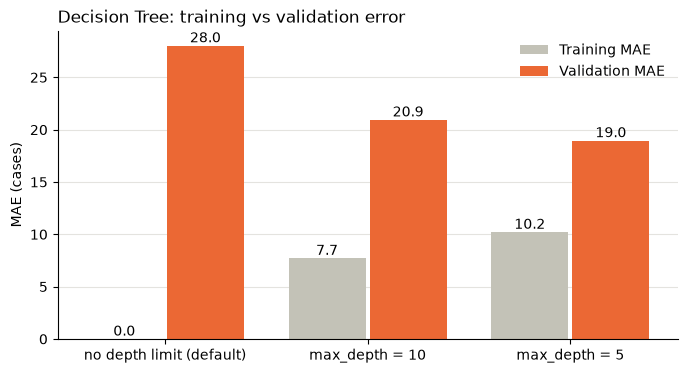

In [9]:
fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(tree_results))
ax.bar(x - 0.2, tree_results["training MAE"], width=0.38, color="#c3c2b7", label="Training MAE")
ax.bar(x + 0.2, tree_results["validation MAE"], width=0.38, color=COLORS["Decision Tree"], label="Validation MAE")
for i, row in tree_results.iterrows():
    ax.text(i - 0.2, row["training MAE"], f"{row['training MAE']:.1f}", ha="center", va="bottom")
    ax.text(i + 0.2, row["validation MAE"], f"{row['validation MAE']:.1f}", ha="center", va="bottom")
ax.set_xticks(x, tree_results["setting"])
ax.set_ylabel("MAE (cases)")
ax.set_title("Decision Tree: training vs validation error", loc="left")
ax.grid(axis="y", color=GRID)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
plt.show()

**What this shows: overfitting**

- The **default tree** has a training MAE of **0.00**: it memorised every training week perfectly. On the 2023 validation weeks, though, its MAE is **28.03**, much worse than persistence (18.17). It learned the noise of the training data, not a general pattern.
- **Limiting the depth** makes the tree simpler. The training error rises, but the validation error falls: 20.95 with `max_depth = 10` and **18.96** with `max_depth = 5`. The gap between training and validation error shrinks.
- The simplest tree generalises best, so `max_depth = 5` is kept as the Decision Tree baseline.

In [10]:
best_tree = tree_results.loc[tree_results["validation MAE"].idxmin()]
print("selected Decision Tree setting:", best_tree["setting"])

results.append({"model": f"Decision Tree ({best_tree['setting']})",
                "MAE": best_tree["validation MAE"], "RMSE": best_tree["validation RMSE"]})

selected Decision Tree setting: max_depth = 5


## 8. Results

Validation scores on 2023, and the change compared with persistence (negative = smaller error than persistence).

In [11]:
results_table = pd.DataFrame(results).set_index("model")
results_table["MAE vs persistence (%)"] = 100 * (results_table["MAE"] / results_table.loc["Persistence", "MAE"] - 1)
results_table["RMSE vs persistence (%)"] = 100 * (results_table["RMSE"] / results_table.loc["Persistence", "RMSE"] - 1)
results_table.round(2)

,MAE,RMSE,MAE vs persistence (%),RMSE vs persistence (%)
model,,,,
Persistence,18.17,41.82,0.00,0.00
Decision Tree (max_depth = 5),18.96,43.01,4.37,2.86


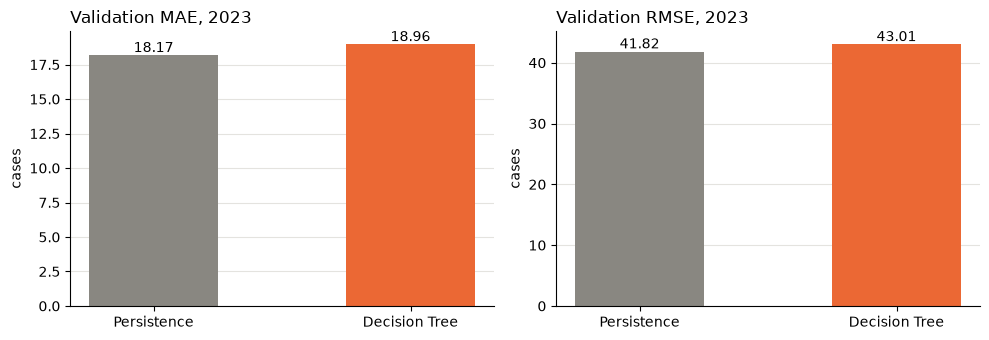

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
bar_colors = [COLORS["Persistence"], COLORS["Decision Tree"]]
labels = ["Persistence", "Decision Tree"]
for ax, metric in zip(axes, ["MAE", "RMSE"]):
    values = results_table[metric].to_numpy()
    ax.bar(labels, values, color=bar_colors, width=0.5)
    for i, v in enumerate(values):
        ax.text(i, v, f"{v:.2f}", ha="center", va="bottom")
    ax.set_title(f"Validation {metric}, 2023", loc="left")
    ax.set_ylabel("cases")
    ax.grid(axis="y", color=GRID)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

## 9. Summary

| Model | Validation MAE (2023) | Validation RMSE (2023) |
|---|---|---|
| Persistence | 18.17 | 41.82 |
| Decision Tree (`max_depth = 5`) | 18.96 | 43.01 |

- **Leakage check:** 52 rows with interpolated weeks (2022 week 37) were removed. The current-week value of these rows had been calculated from next week's cases, i.e. from the target.
- **Persistence is a strong baseline.** Dengue cases change gradually, so "same as this week" is already a good forecast.
- **A single Decision Tree overfits.** Without a depth limit it memorises the training data (training MAE 0) and does badly on new weeks. Even the best depth (5) is about 4% worse than persistence.

**Next:** combine many trees into **ensembles**: a Random Forest (bagging, notebook 05) and XGBoost (boosting, notebook 06). The aim is to reduce the single tree's overfitting and beat persistence.